# Playground — ResNet (Guilherme)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gpeuzinCosta/kws-borda/blob/main/notebooks/experimentos/playground_resnet_guilherme.ipynb)

**Playground que usa os módulos do repositório.** Dados, MFCC, normalização, SpecAugment na GPU, treino,
avaliação, latência e a varredura de configurações vêm de `dados/`, `treino/` e `avaliacao/`, as mesmas funções
do notebook principal e do playground da CNN 1D. Aqui você escreve **só o modelo** e as configurações que quer
testar.

Como usar:
1. Abra no Colab (Ambiente de execução → Alterar tipo → GPU). Para guardar as alterações:
   **Arquivo → Salvar uma cópia no GitHub** ou baixe o `.ipynb` e substitua este arquivo.
2. Implemente o modelo na seção **4. Modelo** (os pontos marcados com `TODO`). O decorador
   `@registrar_modelo` faz a classe do notebook **substituir** o arquivo de `modelos/` nesta sessão: o treino, a
   latência e a varredura passam a usá-la sem copiar nada.
3. Use `fracao < 1` nos hiperparâmetros para iterar rápido; para números de verdade, `fracao = 1.0` e 3 seeds.
4. Quando a arquitetura estiver definida, siga a seção **8. Levando para o repositório**.

O setup clona/atualiza o repositório: o que estiver no GitHub (branch `main`) é o que roda.

## 1. Setup

No Colab, o Google Drive é montado: o `.tar.gz` do GSC, o cache de MFCC e os treinos ficam em
`MyDrive/kws-borda/` e sobrevivem ao fim da sessão (são os mesmos do notebook principal).

In [1]:
#@title Setup — rode esta célula primeiro
#Funciona no Colab (clona o repo e usa o Drive) e localmente/VS Code (usa a pasta do repositório).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/gpeuzinCosta/kws-borda.git"
NO_COLAB = "google.colab" in sys.modules

if NO_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    REPO = Path("/content/kws-borda")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "-q"], check=True)     #pega a versão mais nova dos módulos
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)

    #Drive: cache de MFCC, runs e resultados PERSISTEM entre sessões
    #Disco local (/content/data): áudios extraídos, leitura rápida (o Drive é lento para 100 mil arquivos)
    os.environ["KWS_DRIVE"] = "/content/drive/MyDrive/kws-borda"
    os.environ["KWS_DATA"] = "/content/data"
else:
    #Local: sobe a partir da pasta atual até achar a raiz do repositório
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())

#A raiz do repo no sys.path deixa importar as pastas: configs, dados, modelos, treino, avaliacao
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import torch
from configs import pastas_projeto, escolher_device

PASTAS = pastas_projeto()
DOWNLOADS = Path(os.environ.get("KWS_DRIVE", REPO)) / "downloads"     #.tar.gz/.zip baixados UMA vez
device = escolher_device()
commit = subprocess.run(["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True).stdout.strip()

print(f"Colab: {NO_COLAB} | device: {device} | commit do código: {commit}")
print(f"torch {torch.__version__} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else '—'}")
for nome, p in PASTAS.items():
    print(f"  {nome:10s} -> {p}")

Mounted at /content/drive
Colab: True | device: cuda | commit do código: ff40ccb
torch 2.14.1+cu130 | GPU: NVIDIA L4
  dados      -> /content/data
  cache      -> /content/drive/MyDrive/kws-borda/cache
  runs       -> /content/drive/MyDrive/kws-borda/runs
  resultados -> /content/drive/MyDrive/kws-borda/runs


## 2. Hiperparâmetros

Vêm de `configs/base.yaml` (regras comuns a todos) + `configs/<modelo>.yaml` (só o que muda). Aqui ficam só as
sobrescritas deste playground.

In [2]:
from configs import carregar_config

NOME_MODELO = "resnet"

hyperparameters = carregar_config(NOME_MODELO,
                                  fracao=1,      #fração do TREINO (1.0 = tudo). Val e teste são sempre completos
                                  epocas=20,
                                  seeds=[0, 1, 2],       #[0, 1, 2] para os números de verdade
                                  pool=[3, 4],         #res8 (lista, não tupla: o config.yaml do run não aceita tupla)
                                  dilatacao=False,
                                  conv_extra=False)
hyperparameters

{'dataset': 'speech_commands_v2',
 'tarefa': 'gsc35',
 'sample_rate': 16000,
 'duracao_s': 1.0,
 'n_mfcc': 40,
 'janela_ms': 30,
 'passo_ms': 10,
 'center': True,
 'n_mels': 40,
 'f_min': 20,
 'f_max': 7600,
 'normalizacao': 'global',
 'spec_augment': True,
 'fracao': 1,
 'epocas': 20,
 'batch_size': 128,
 'learning_rate': 0.003,
 'weight_decay': 0.01,
 'otimizador': 'adamw',
 'scheduler': 'onecycle',
 'label_smoothing': 0.1,
 'seeds': [0, 1, 2],
 'num_workers': 0,
 'latencia_repeticoes': 300,
 'latencia_aquecimento': 30,
 'latencia_threads': 1,
 'snrs_db': [20, 10, 5, 0, -5],
 'margem_pp': 2.0,
 'modelo': 'resnet',
 'canais': 45,
 'n_blocos': 3,
 'pool': [3, 4],
 'dilatacao': False,
 'conv_extra': False,
 'n_classes': 35,
 'n_frames': 101}

## 3. Dados

O GSC v2 é baixado para o Drive **uma vez**, e o MFCC de treino/val/teste é calculado uma vez e guardado em
cache (`carregar_dados`). O `criar_dataloaders` normaliza com as estatísticas do treino e entrega o batch inteiro
com um fatiamento; o SpecAugment é aplicado depois, no batch, na GPU, dentro do treino.

In [3]:
import subprocess, sys
from dados import classes_da_tarefa, criar_dataloaders
from treino.varredura import carregar_dados

subprocess.run([sys.executable, str(REPO / "dados" / "baixar.py"), "--dataset", "gsc",
                "--destino", str(PASTAS["dados"]), "--arquivos", str(DOWNLOADS)], check=True)
RAIZ_GSC = PASTAS["dados"] / "gsc"
CLASSES = classes_da_tarefa(hyperparameters["tarefa"])

dados = carregar_dados(hyperparameters, RAIZ_GSC, PASTAS["cache"])
loaders, (media, desvio) = criar_dataloaders(hyperparameters, dados)

xb, yb = next(iter(loaders["treino"]))
print("batch:", tuple(xb.shape), "| treino:", len(loaders["treino"].dataset), "áudios")   #esperado: (128, n_mfcc, n_frames)

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}
batch: (128, 40, 101) | treino: 84843 áudios


## 4. Modelo

**Contrato** (o mesmo da bancada):
- entrada `x`: `(B, n_mfcc, n_frames)`, o MFCC normalizado (40 × 101 no padrão, 10 × 49 no `hello_edge`;
  não fixe esses números no código);
- saída: logits `(B, n_classes)`;
- a última camada se chama `self.head`;
- o `__init__` recebe `n_classes, n_mfcc, n_frames` e, depois, os hiperparâmetros da arquitetura (que vêm do
  `configs/<modelo>.yaml` e das configurações da varredura).

A `ResNet` abaixo é o esqueleto: implemente as camadas e o `forward`. Os hiperparâmetros da arquitetura
(`canais`, `n_blocos`) vêm do `configs/resnet.yaml` e podem ser variados na varredura (seção 7).

In [4]:
import torch
from modelos import registrar_modelo


@registrar_modelo("resnet", familia="ResNet", referencia="He et al. 2016; Tang & Lin 2018 (res8)")
class ResNet(torch.nn.Module):

    def __init__(self, n_classes, n_mfcc=40, n_frames=101, canais=45, n_blocos=3,
                 pool=(3, 4), dilatacao=False, conv_extra=False):      #pool, dilatacao, conv_extra
        super().__init__()

        k = 3   #kernel 3x3 em todas as camadas, como no Tang & Lin

        #Entrada: 1 canal -> canais
        self.conv0 = torch.nn.Conv2d(1, canais, k, padding=1, bias=False) #o Batch norm vai anular qualquer bias, pois subtrai a media do batch
        self.bn0   = torch.nn.BatchNorm2d(canais)

        #NOVO: res8 usa pool 3x4, res26 usa 2x2 e res15 não usa pooling
        if pool is None:
            self.pool = torch.nn.Identity()
        else:
            self.pool = torch.nn.AvgPool2d(pool)

        #Blocos residuais: 2 convs por bloco (+1 conv extra no res15)
        n_convs = 2 * n_blocos
        if conv_extra:
            n_convs = n_convs + 1
        self.convs = torch.nn.ModuleList()
        self.bns   = torch.nn.ModuleList()
        for i in range(1, n_convs + 1):
            if dilatacao:
                d = 2 ** (i // 3)                    #res15: 1,1,2,2,2,4,4,4,8,8,8,16,16
            else:
                d = 1
            #padding = d mantém o tamanho do mapa, para a soma com o atalho bater
            self.convs.append(torch.nn.Conv2d(canais, canais, k, padding=d, dilation=d, bias=False))
            self.bns.append(torch.nn.BatchNorm2d(canais))

        self.relu = torch.nn.ReLU()
        self.gap  = torch.nn.AdaptiveAvgPool2d((1, 1))
        self.head = torch.nn.Linear(canais, n_classes)    #última camada sempre com o nome `head`

    def forward(self, x):
        #x: (B, n_mfcc, n_frames) -> logits (B, n_classes)
        x = x.unsqueeze(1)      #(B, 1, n_mfcc, n_frames): 1 canal, como uma imagem em tons de cinza

        x = self.relu(self.bn0(self.conv0(x))) #primeira conv com norm e relu
        x = self.pool(x)

        #cada bloco = conv -> norm -> ReLu -> conv -> norm, soma o atalho, ReLu
        for b in range(len(self.convs) // 2):
            atalho = x
            y = self.relu(self.bns[2 * b](self.convs[2 * b](x)))
            y = self.bns[2 * b + 1](self.convs[2 * b + 1](y))
            x = self.relu(y + atalho)

        #conv extra do res15 (sobra 1 conv quando o total é ímpar)
        if len(self.convs) % 2 == 1:
            x = self.relu(self.bns[-1](self.convs[-1](x)))

        #Descarta posicoes e mantem so uma intensidade media para a fully connected ter menos parametros
        x = self.gap(x)                               # (B, canais, 1, 1)
        x = x.view(x.size(0), -1)                     # (B, canais)

        return self.head(x)                           # (B, n_classes) — logits crus

In [5]:
from modelos import criar_modelo
from avaliacao import custo

modelo = criar_modelo(NOME_MODELO, hyperparameters)
print("classe usada:", type(modelo).__name__, "| definida em:", type(modelo).__module__)   #'__main__' = a deste notebook

#Contrato
saida = modelo.eval()(xb)
print("entrada:", tuple(xb.shape), "| saída:", tuple(saida.shape))      #esperado: (128, 35)
assert saida.shape == (len(xb), len(CLASSES)), f"saída {tuple(saida.shape)}, esperado ({len(xb)}, {len(CLASSES)})"
assert hasattr(modelo, "head"), "a última camada deve se chamar `head`"

c = custo(modelo)
print(f"parâmetros: {c['params']:,} | {c['kb_int8']:.1f} KB int8 | MACs: {c['macs']:,}")

classe usada: ResNet | definida em: __main__
entrada: (128, 40, 101) | saída: (128, 35)
parâmetros: 111,995 | 109.4 KB int8 | MACs: 37,176,525


In [6]:
import pandas as pd

#As 6 famílias do Tang & Lin (2018): o que muda em relação ao hyperparameters
familias = {
    'res8':         {'canais': 45, 'n_blocos': 3,  'pool': [3, 4], 'dilatacao': False, 'conv_extra': False},
    'res8-narrow':  {'canais': 19, 'n_blocos': 3,  'pool': [3, 4], 'dilatacao': False, 'conv_extra': False},
    'res15':        {'canais': 45, 'n_blocos': 6,  'pool': None,   'dilatacao': True,  'conv_extra': True},
    'res15-narrow': {'canais': 19, 'n_blocos': 6,  'pool': None,   'dilatacao': True,  'conv_extra': True},
    'res26':        {'canais': 45, 'n_blocos': 12, 'pool': [2, 2], 'dilatacao': False, 'conv_extra': False},
    'res26-narrow': {'canais': 19, 'n_blocos': 12, 'pool': [2, 2], 'dilatacao': False, 'conv_extra': False},
}

#Valores da Tabela do paper, só como referência (eles usam 12 classes, nós 35)
paper = {'res8': (110_000, 30e6), 'res8-narrow': (19_900, 5.65e6),
         'res15': (238_000, 894e6), 'res15-narrow': (42_600, 160e6),
         'res26': (438_000, 380e6), 'res26-narrow': (78_400, 77.1e6)}

x_teste = xb[:8]    #só 8 exemplos: o res15 em CPU com batch 128 demora
linhas = []
for nome, mudancas in familias.items():
    hp = {**hyperparameters, **mudancas}      #o hyperparameters original não é alterado
    modelo = criar_modelo(NOME_MODELO, hp)

    #Contrato
    with torch.no_grad():
        saida = modelo.eval()(x_teste)
    assert saida.shape == (len(x_teste), len(CLASSES)), f"{nome}: saída {tuple(saida.shape)}"

    c = custo(modelo)
    linhas.append({'familia': nome,
                   'params': c['params'], 'params paper': paper[nome][0],
                   'MACs (M)': c['macs'] / 1e6, 'mult paper (M)': paper[nome][1] / 1e6,
                   'KB int8': c['kb_int8']})

display(pd.DataFrame(linhas).round(1))

,familia,params,params paper,MACs (M),mult paper (M),KB int8
0,res8,111995,110000,37.2,30.0,109.4
1,res8-narrow,20631,19900,7.0,5.6,20.1
2,res15,240200,238000,958.8,894.0,234.6
3,res15-narrow,43640,42600,171.3,160.0,42.6
4,res26,441665,438000,439.0,380.0,431.3
5,res26-narrow,79797,78400,78.7,77.1,77.9


## 5. Treino e avaliação de um baseline

O loop único da bancada (`treino/loop.py`): AdamW, OneCycle, entropia cruzada com label smoothing, SpecAugment
no batch e os pesos da melhor época na validação.

treinando: resnet | canais: 45 | n_blocos: 3 | pool: [3, 4] | dilatacao: False | conv_extra: False
época  1/20 | perda treino: 3.1077 | perda val: 2.4929 | acurácia val: 43.40% | 12s
época  2/20 | perda treino: 2.0104 | perda val: 1.7453 | acurácia val: 63.07% | 10s
época  3/20 | perda treino: 1.4718 | perda val: 1.8889 | acurácia val: 61.25% | 10s
época  4/20 | perda treino: 1.2852 | perda val: 1.3568 | acurácia val: 79.68% | 10s
época  5/20 | perda treino: 1.1933 | perda val: 1.5023 | acurácia val: 74.60% | 10s
época  6/20 | perda treino: 1.1358 | perda val: 1.1814 | acurácia val: 86.12% | 10s
época  7/20 | perda treino: 1.0921 | perda val: 1.0454 | acurácia val: 90.00% | 10s
época  8/20 | perda treino: 1.0580 | perda val: 1.0016 | acurácia val: 91.78% | 10s
época  9/20 | perda treino: 1.0309 | perda val: 0.9667 | acurácia val: 92.26% | 10s
época 10/20 | perda treino: 1.0109 | perda val: 0.9444 | acurácia val: 92.82% | 10s
época 11/20 | perda treino: 0.9897 | perda val: 0.9158 | acur

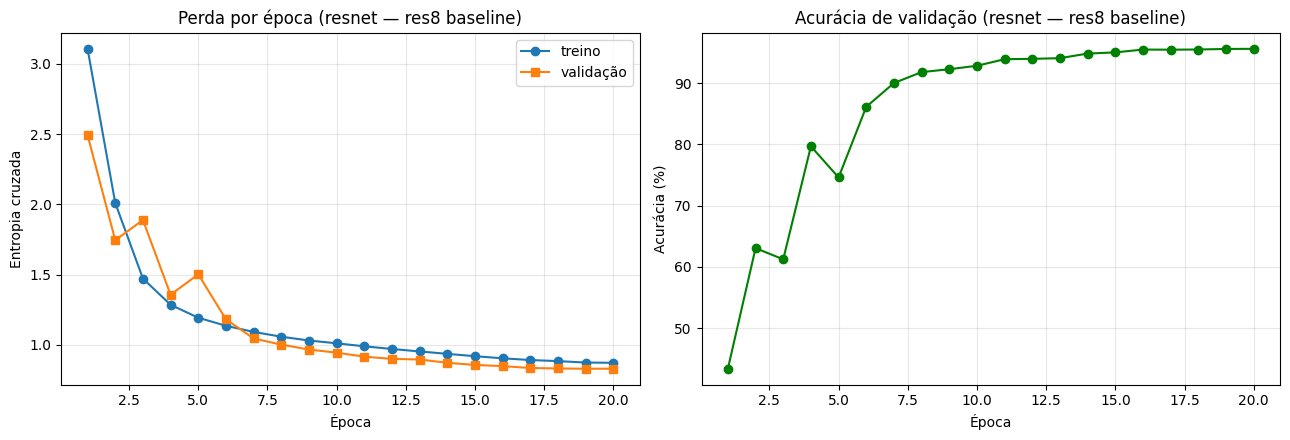

Gap (val - treino): -0.0421 | 3.3 min


In [7]:
from treino import treinar
from avaliacao.graficos import curvas_treino

#mostra qual ResNet vai ser treinada
#resnet8 é o baseline
print(f'treinando: {NOME_MODELO} | canais: {hyperparameters["canais"]} | n_blocos: {hyperparameters["n_blocos"]} | '
      f'pool: {hyperparameters["pool"]} | dilatacao: {hyperparameters["dilatacao"]} | conv_extra: {hyperparameters["conv_extra"]}')

model_base, hist_base = treinar(criar_modelo(NOME_MODELO, hyperparameters), loaders, hyperparameters,
                                seed=hyperparameters["seeds"][0], device=device)
curvas_treino(hist_base, titulo=f"({NOME_MODELO} — res8 baseline)")      # título diz qual família
print(f'Gap (val - treino): {hist_base["gap"]:+.4f} | {hist_base["tempo_min"]:.1f} min')

teste | acurácia: 95.15% | F1 macro: 0.9456


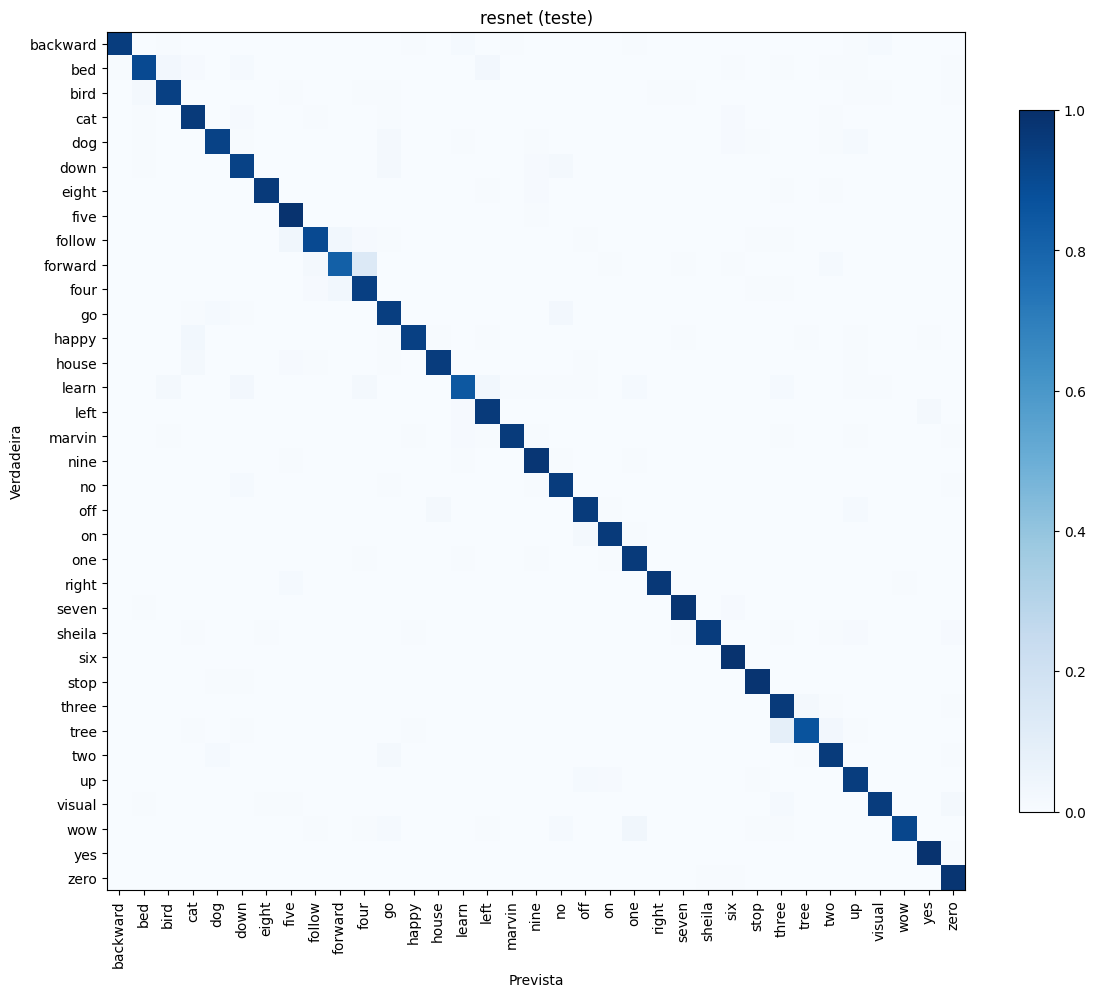

,verdadeira,prevista,fração
0,forward,four,0.135484
1,tree,three,0.088083
2,follow,five,0.034884
3,wow,one,0.033981
4,learn,left,0.031056
5,happy,cat,0.029557
6,follow,forward,0.029070
7,four,forward,0.027500
8,tree,two,0.025907
9,go,no,0.024876


,precisao,revocacao,f1,exemplos
forward,0.898,0.842,0.869,146
up,0.893,0.934,0.913,350
tree,0.947,0.893,0.919,159
four,0.906,0.957,0.931,373
no,0.954,0.919,0.936,406
follow,0.946,0.932,0.939,132
visual,0.969,0.914,0.941,139
bed,0.935,0.948,0.942,213
bird,0.950,0.934,0.942,182
off,0.948,0.936,0.942,373


In [8]:
import pandas as pd
from treino import prever
from avaliacao import acuracia, f1_macro, matriz_confusao, top_confusoes, relatorio_por_classe
from avaliacao.graficos import plot_matriz_confusao

y_pred, y_true = prever(model_base, loaders["teste"])
print(f"teste | acurácia: {acuracia(y_pred, y_true)*100:.2f}% | F1 macro: {f1_macro(y_pred, y_true):.4f}")

cm = matriz_confusao(y_pred, y_true, len(CLASSES))
plot_matriz_confusao(cm, CLASSES, titulo=f"{NOME_MODELO} (teste)")
display(pd.DataFrame(top_confusoes(cm, CLASSES, k=10), columns=["verdadeira", "prevista", "fração"]))

#Ranking de F1 por classe na VALIDAÇÃO (do pior para o melhor)
y_pred_val, y_true_val = prever(model_base, loaders["val"])
display(relatorio_por_classe(y_pred_val, y_true_val, CLASSES).round(3))

## 6. Latência (MFCC × rede)

Protocolo da hipótese (b): CPU com **1 thread**, **batch 1**, aquecimento e mediana; MFCC, normalização e rede
medidos separados, em rodadas, com aviso se a medida oscilar.

In [9]:
from avaliacao import medir_latencia

lat = medir_latencia(model_base, hyperparameters, media, desvio)
print(f"CPU: {lat['cpu']}")
print(f"MFCC: {lat['mfcc_ms']:.3f} ms | normalização: {lat['norm_ms']:.3f} ms | rede: {lat['rede_ms']:.3f} ms")
print(f"pré-processamento / rede = {lat['preproc_sobre_rede']:.2f}x | estável: {lat['estavel']}")

CPU: Intel(R) Xeon(R) CPU @ 2.20GHz
MFCC: 0.717 ms | normalização: 0.008 ms | rede: 3.027 ms
pré-processamento / rede = 0.24x | estável: True


## 7. Varredura: quanto dá para encolher?

Cada configuração é `(nome, o que muda em relação ao hyperparameters)`. A primeira se chama `baseline`: é a
referência do critério do projeto (o **menor** modelo até 2 p.p. abaixo dela na **validação**).
Com `retreinar=False`, o que já foi treinado (pesos no Drive, tabela `runs/varredura_<modelo>.csv`) é carregado.

In [10]:
from treino.varredura import (rodar_varredura, medir_latencias_varredura, anexar_latencias, montar_resumo,
                              tabela_slide, escolher_vencedor, matrizes_escolhidos)


#mesmo desenho da varredura da CNN 1D (ablações só no baseline + encolher o modelo, com as duas entradas)
configs_varredura = [('baseline', {})]      #= res8 40x101: a referência, sempre a primeira

#Ablações de treino, só no baseline (as mesmas da CNN 1D, para comparar entre famílias)
configs_varredura.append(('sem spec_augment',  {'spec_augment': False}))
configs_varredura.append(('norm por_amostra',  {'normalizacao': 'por_amostra'}))
configs_varredura.append(('sem weight_decay',  {'weight_decay': 0.0}))

#Candidatos a "menor modelo": tudo que tem MENOS parâmetros que o res8 (+ o próprio res8, para o hello_edge)
candidatos = {
    'res8':           familias['res8'],
    'res8-narrow':    familias['res8-narrow'],
    'res15-narrow':   familias['res15-narrow'],
    'res26-narrow':   familias['res26-narrow'],
    'res8 canais 12': {**familias['res8'], 'canais': 12},     #achar onde a acurácia desaba
    'res8 canais 8':  {**familias['res8'], 'canais': 8},
}

entradas = {
    '':            {},
    'hello_edge':  {'n_mfcc': 10, 'janela_ms': 40, 'passo_ms': 20, 'center': False},
}

#Entrada por fora e modelo por dentro: o MFCC só troca uma vez
for nome_entrada, mudancas_entrada in entradas.items():
    for nome_candidato, mudancas_candidato in candidatos.items():
        if nome_entrada == '':
            nome = nome_candidato
        else:
            nome = f'{nome_candidato} + {nome_entrada}'

        if nome == 'res8':
            continue        #o res8 com a entrada padrão já é o baseline

        configs_varredura.append((nome, {**mudancas_candidato, **mudancas_entrada}))

for nome, mudancas in configs_varredura:
    print(nome)

SEEDS = hyperparameters["seeds"]
tabela, modelos = rodar_varredura(NOME_MODELO, configs_varredura, hyperparameters, SEEDS, RAIZ_GSC, PASTAS,
                                  retreinar=False, device=device)

baseline
sem spec_augment
norm por_amostra
sem weight_decay
res8-narrow
res15-narrow
res26-narrow
res8 canais 12
res8 canais 8
res8 + hello_edge
res8-narrow + hello_edge
res15-narrow + hello_edge
res26-narrow + hello_edge
res8 canais 12 + hello_edge
res8 canais 8 + hello_edge


resnet | seed 0:   0%|          | 0/15 [03:19<?, ?it/s, baseline]

baseline                       |  111995 params | melhor acc val=95.85% (época 20) | 3.3 min


resnet | seed 0:   7%|▋         | 1/15 [06:32<46:41, 200.12s/it, sem spec_augment]

sem spec_augment               |  111995 params | melhor acc val=95.25% (época 17) | 3.2 min


resnet | seed 0:  13%|█▎        | 2/15 [09:52<42:30, 196.20s/it, norm por_amostra]

... (92 outputs left out)

res8 canais 12 + hello_edge    |    8507 params | melhor acc val=87.38% (época 20) | 1.3 min


resnet | seed 2:  93%|█████████▎| 14/15 [59:53<02:25, 145.88s/it, res8 canais 8 + hello_edge]

res8 canais 8 + hello_edge     |    3955 params | melhor acc val=80.22% (época 17) | 1.3 min


resnet | seed 2: 100%|██████████| 15/15 [59:53<00:00, 239.56s/it, res8 canais 8 + hello_edge]


baseline                   | MFCC 0.713 ms | norm 0.008 ms | rede 3.033 ms | preproc/rede 0.24x | estável: True | rede nas passadas: 3.154 / 3.033 / 3.045
sem spec_augment           | MFCC 0.712 ms | norm 0.008 ms | rede 3.036 ms | preproc/rede 0.24x | estável: True | rede nas passadas: 3.049 / 3.036 / 3.163
norm por_amostra           | MFCC 0.711 ms | norm 0.071 ms | rede 3.011 ms | preproc/rede 0.26x | estável: True | rede nas passadas: 3.028 / 3.038 / 3.011
sem weight_decay           | MFCC 0.708 ms | norm 0.008 ms | rede 3.011 ms | preproc/rede 0.24x | estável: True | rede nas passadas: 3.023 / 3.046 / 3.011
res8-narrow                | MFCC 0.688 ms | norm 0.008 ms | rede 1.255 ms | preproc/rede 0.55x | estável: True | rede nas passadas: 1.257 / 1.274 / 1.255
res15-narrow               | MFCC 0.704 ms | norm 0.008 ms | rede 13.555 ms | preproc/rede 0.05x | estável: True | rede nas passadas: 13.555 / 14.183 / 13.686
res26-narrow               | MFCC 0.706 ms | norm 0.008 ms | rede 

,Entrada,Params,KB int8,MACs,Acc val (%),Acc teste (%),F1 teste (%),MFCC (ms),Rede (ms),Pré-proc / rede,Dif. val vs baseline (p.p.),Dentro de 2 p.p.
experimento,,,,,,,,,,,,
baseline,40x101,111995,109.4,37176525,95.82 ± 0.03,95.28 ± 0.17,94.85 ± 0.17,0.713,3.033,0.24,0.00,True
sem spec_augment,40x101,111995,109.4,37176525,95.22 ± 0.08,94.84 ± 0.03,94.37 ± 0.05,0.712,3.036,0.24,-0.59,True
norm por_amostra,40x101,111995,109.4,37176525,95.29 ± 0.16,94.84 ± 0.22,94.37 ± 0.22,0.711,3.011,0.26,-0.52,True
sem weight_decay,40x101,111995,109.4,37176525,95.62 ± 0.09,95.09 ± 0.14,94.63 ± 0.17,0.708,3.011,0.24,-0.20,True
res8-narrow,40x101,20631,20.1,7027055,92.89 ± 0.21,91.97 ± 0.13,91.26 ± 0.15,0.688,1.255,0.55,-2.93,False
res15-narrow,40x101,43640,42.6,171328985,95.75 ± 0.10,95.19 ± 0.09,94.72 ± 0.05,0.704,13.555,0.05,-0.07,True
res26-narrow,40x101,79797,77.9,78667505,95.40 ± 0.14,94.61 ± 0.18,94.14 ± 0.21,0.706,6.322,0.11,-0.41,True
res8 canais 12,40x101,8507,8.3,2963940,89.38 ± 0.19,87.75 ± 0.49,86.70 ± 0.45,0.683,0.950,0.73,-6.44,False
res8 canais 8,40x101,3955,3.9,1414360,82.21 ± 0.56,80.45 ± 0.44,77.85 ± 0.95,0.706,0.805,0.89,-13.60,False


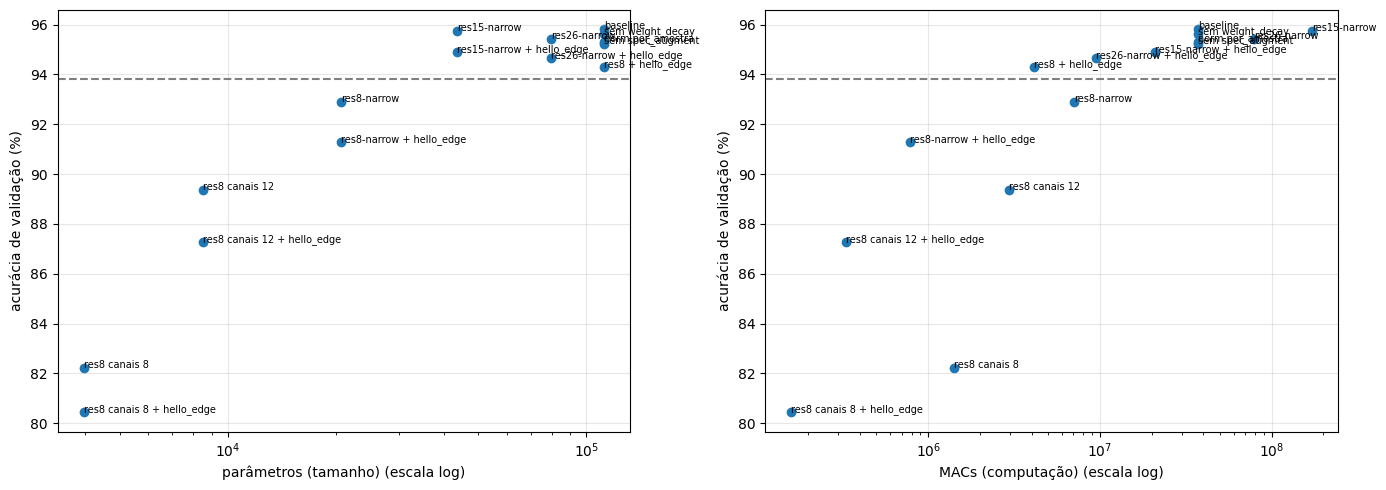

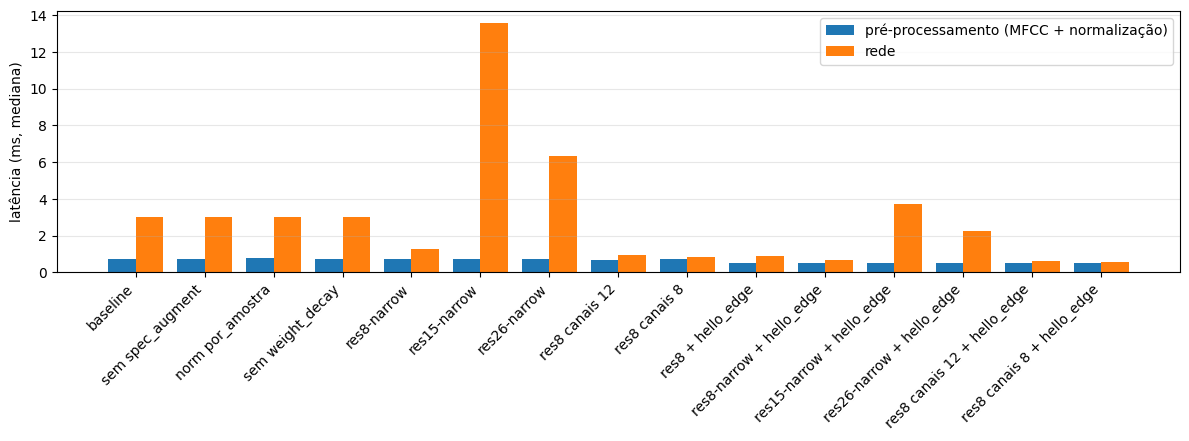

In [11]:
from avaliacao.graficos import acuracia_vs_custo_varredura, barras_preproc_rede

latencias = medir_latencias_varredura(NOME_MODELO, configs_varredura, hyperparameters)
tabela = anexar_latencias(tabela, latencias)
resumo = montar_resumo(tabela, hyperparameters["fracao"], hyperparameters["margem_pp"])

display(tabela_slide(resumo))
acuracia_vs_custo_varredura(resumo, hyperparameters["margem_pp"])
barras_preproc_rede(resumo)

Menor modelo dentro de 2 p.p. do baseline: res15-narrow + hello_edge (43,640 parâmetros, 20,780,585 MACs)
gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


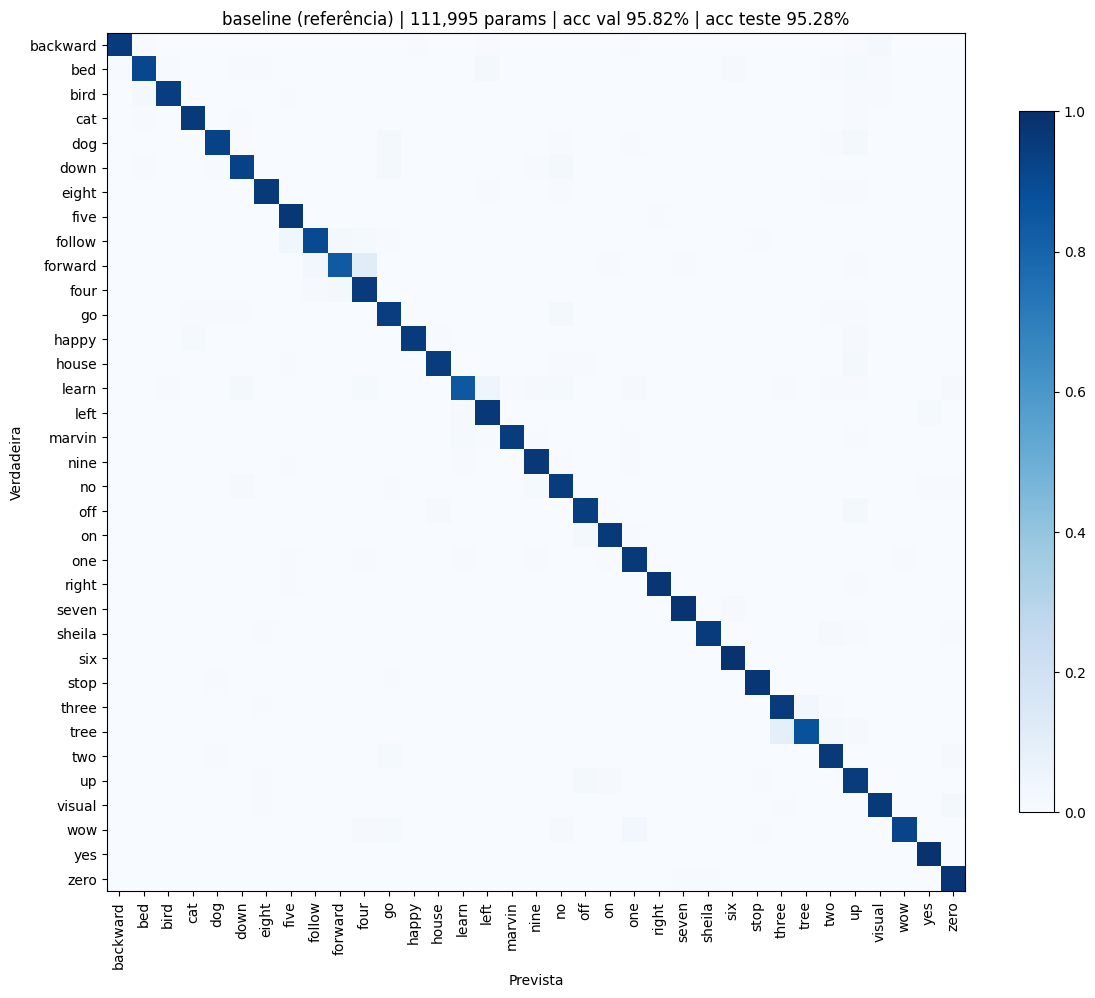

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


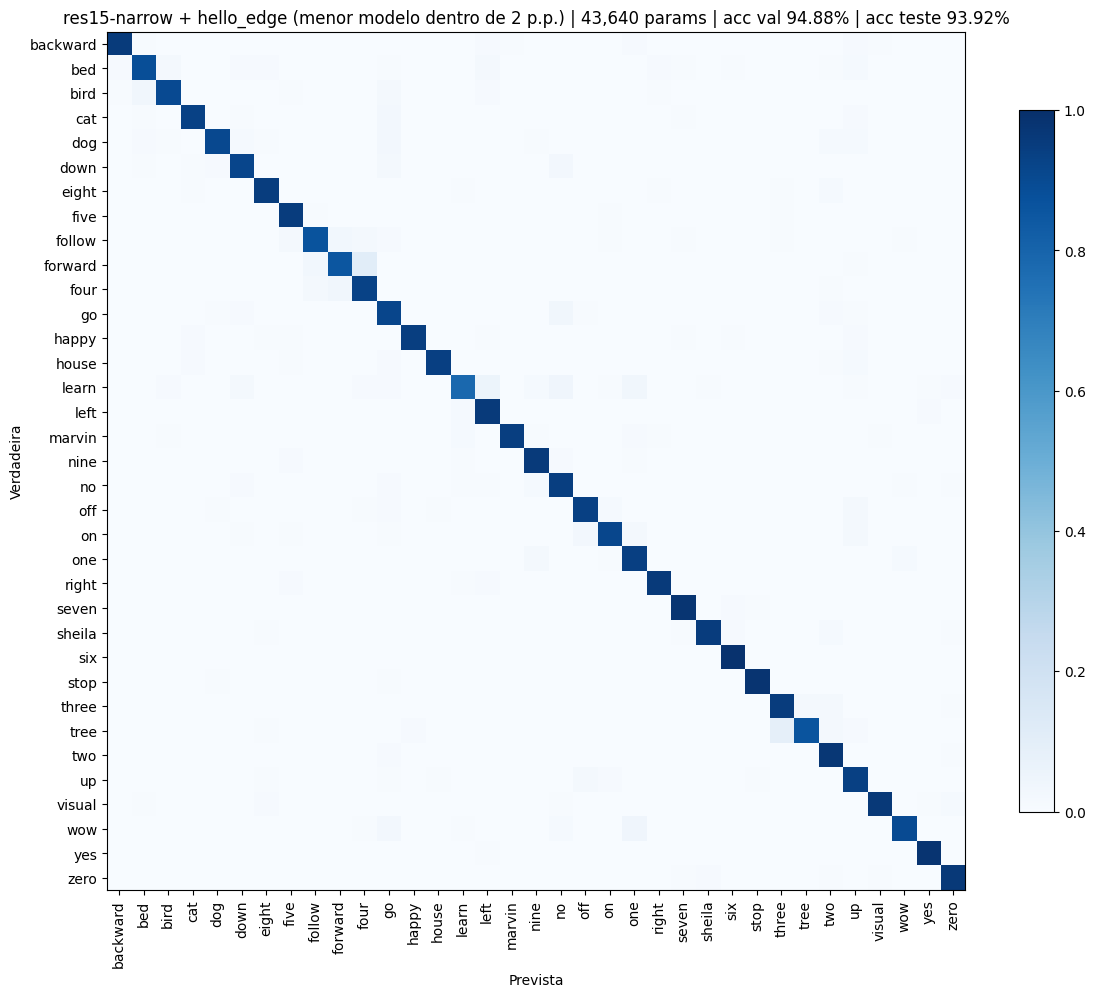

gsc35 {'treino': 84843, 'val': 9981, 'teste': 11005}


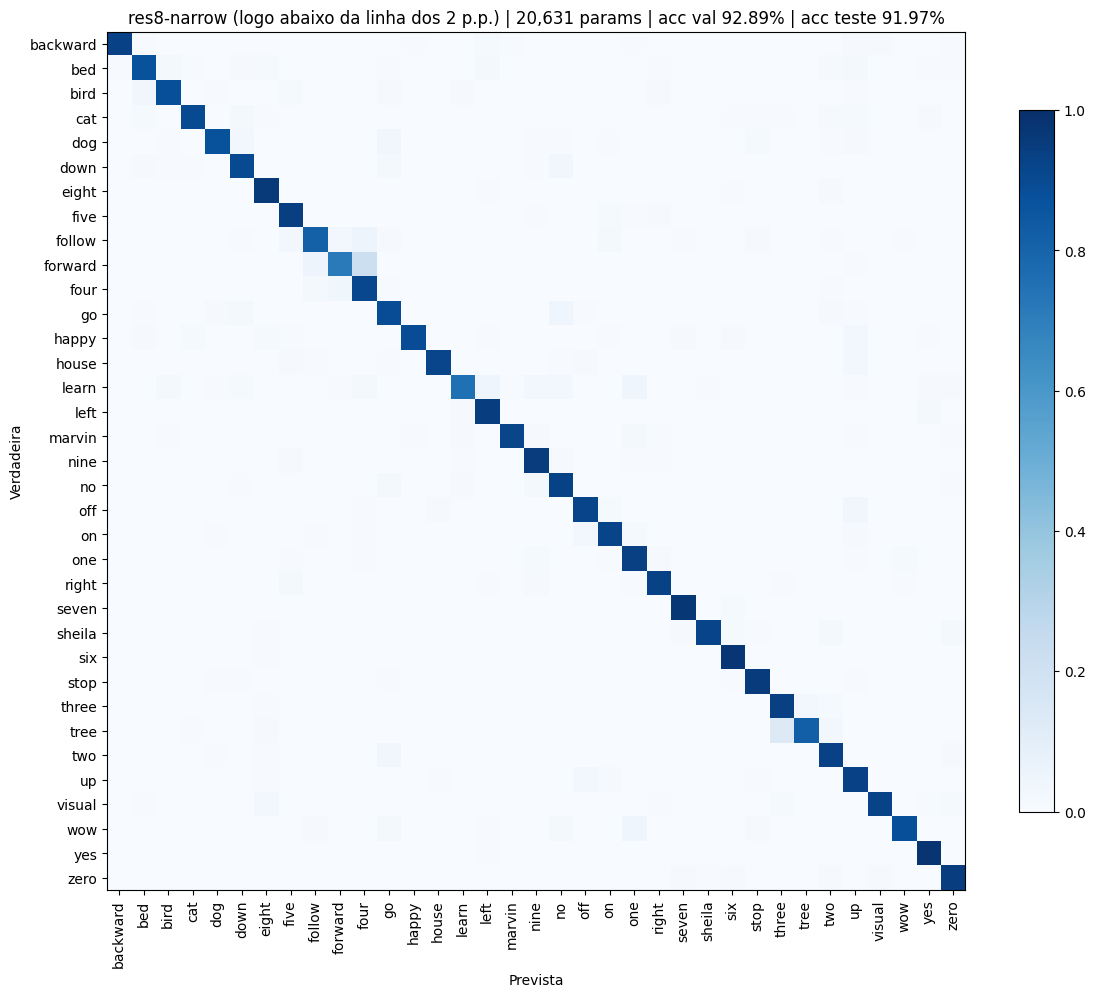

In [12]:
vencedor = escolher_vencedor(resumo)

#Matrizes de confusão (no TESTE, somadas entre as seeds): baseline, vencedor e o que ficou logo abaixo da linha
matrizes_escolhidos(resumo, modelos, configs_varredura, hyperparameters, SEEDS, RAIZ_GSC, PASTAS["cache"])

## 8. Levando para o repositório

Quando a arquitetura estiver definida (o mesmo caminho da CNN 1D):
1. Copie a classe para `modelos/resnet.py`, no lugar do esqueleto, e mude `IMPLEMENTADO = True`.
2. Ponha a configuração vencedora em `configs/resnet.yaml` (seção `modelo:` e, se a entrada mudar, a seção
   `dados:` com o MFCC, como no `configs/cnn1d.yaml`).
3. Copie a lista `configs_varredura` para `treino/varredura.py` como `CONFIGS_RESNET`, com o MFCC e a arquitetura
   do baseline explícitos em cada linha (o YAML passa a guardar o vencedor, não o baseline).
4. Rode `pytest` para conferir o contrato.
5. No notebook principal, acrescente o estudo da ResNet no formato da §6.1 (CNN 1D).

